### Flohmarkt in Langdorf – Lösung Schritt für Schritt

*39. Bundeswettbewerb Informatik (2020/2021), 2. Runde, Aufgabe 1*

Einmal im Monat findet in Langdorf ein großer Flohmarkt von 8 Uhr bis 18 Uhr statt. Hier bieten Privatleute Dinge an, die sie nicht
mehr brauchen. Der Flohmarkt ist sehr beliebt; daher ist eine Voranmeldung nötig. Typischerweise können nicht alle Voranmeldungen
berücksichtigt werden.

Standplätze werden meterweise vermietet. Mietbeginn und -ende sind jeweils zur vollen Stunde. Die Mietkosten betragen 1 Euro pro
Stunde und Meter. Bei ihrer Voranmeldung geben die Anbieter an, zu welcher Zeit sie wie viele Meter mieten möchten. Beispielsweise
möchten Anna von 11 bis 16 Uhr einen Stand von 5 Metern, Sophie von 16 bis 18 Uhr einen Stand von 3 Metern und Max von 10 bis 14 Uhr
einen Stand von 4 Metern haben. In diesem Fall kann Sophie dort untergebracht werden, wo Annas Stand zuvor war. Max jedoch wird
einen anderen Standplatz bekommen müssen.

Der Flohmarkt zieht sich in einer Reihe entlang der Hauptstraße und ist 1000 Meter lang. Diese recht große Ausdehnung des
Flohmarktes macht die Verwaltung der Voranmeldungen jedoch schwierig.

#### Aufgabe

Schreibe ein Programm, das den Organisatoren des Flohmarkts hilft. Dein Programm soll eine Liste von Voranmeldungen der Anbieter
einlesen und eine Auswahl aus diesen so treffen, dass für alle ausgewählten Anmeldungen ein Standplatz gefunden werden kann und die
Mieteinnahmen möglichst hoch sind.

Wende dein Programm mindestens auf die Beispiele an, die du auf den BWINF-Webseiten findest.

#### Beispieldaten

Im Ordner `beispieldaten` stehen `flohmarkt1.txt` bis `flohmarkt7.txt`. Die erste Zeile enthält die Zahl `n` der Voranmeldungen,
danach folgt pro Voranmeldung eine Zeile `Mietbeginn Mietende Länge`, zum Beispiel `8 15 249` (von 8 bis 15 Uhr, 249 Meter). Die
Dateien haben keine Formatbeschreibung; so lesen wir sie.

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Stände als Rechtecke:** Ein Stand belegt ein Rechteck aus Zeit (Stunden) und Ort (Meter). Der ganze Flohmarkt ist ein Rechteck aus
  10 Stunden mal 1000 Metern, also 10 000 „Stundenmetern“. Mehr als 10 000 Euro kann man nie einnehmen.
- **Greedy (gierig):** Die Anmeldungen der Reihe nach durchgehen und jeder den ersten freien Platz geben, wenn es einen gibt. Wie gut
  das ist, hängt stark von der **Reihenfolge** ab.
- **Zufall und Neustarts:** Viele zufällige Reihenfolgen ausprobieren und die beste behalten (mit festem Startwert, damit alles
  reproduzierbar ist).
- **Große Nachbarschaftssuche („räumen und neu füllen“):** Einen Ausschnitt einer guten Lösung leer räumen, neu füllen und das Ergebnis
  nur behalten, wenn es nicht schlechter ist.
- **Backtracking:** Für eine Belegung ganz ohne Lücke immer die erste freie Stelle füllen und bei einer Sackgasse den letzten Stand
  wieder wegnehmen.
- **Obere Schranke:** Zu jeder Stunde können höchstens 1000 Meter vermietet werden. Wer eine Lösung findet, die eine solche Schranke
  erreicht, weiß: Besser geht es nicht.

**Nützliche Funktionen und Bibliotheken**
- Bitmasken: Die Stunden von 8 bis 18 Uhr sind die Bits 0 bis 9 einer ganzen Zahl. `a & b` ist die Schnittmenge, `a | b` die
  Vereinigung, `a & ~b` nimmt die Bits von `b` heraus.
- `random.Random(1)` ist ein Zufallsgenerator mit festem Startwert, `shuffle` mischt eine Liste.
- Sortieren von Tupeln: `liste.sort()` vergleicht Tupel von links nach rechts. Mit `(-miete, i)` steht die größte Miete vorne.
- `matplotlib` für die Zeichnung der Belegung (nur am Ende).

## Die Idee

**Was ist zu entscheiden?** Für jede Anmeldung, ob sie angenommen wird, und wenn ja, ab welchem Meter `x` ihr Stand beginnt (dann belegt
er die Meter `x` bis `x + Länge - 1`). Zwei Stände stören sich nur, wenn sie sich **zeitlich und räumlich** überschneiden. Die Zeit liegt
durch die Anmeldung fest, wählen kann man nur den Ort.

**Wie schwer ist das?** Die Lösungshinweise zeigen, dass die Aufgabe NP-schwer ist: Wenn alle Stände von 8 bis 18 Uhr gehen, muss man aus
Längen eine Teilmenge mit Summe möglichst nah an 1000 auswählen (Teilsummenproblem). Wir rechnen deshalb mit Heuristiken, prüfen am Ende
aber mit einer Schranke, wie gut wir sind.

**Plan.**
1. Belegungsplan und ein Greedy-Verfahren mit der ersten passenden Lücke.
2. Verschiedene Reihenfolgen vergleichen.
3. Für die kleinen Beispiele viele zufällige Reihenfolgen.
4. Für die großen Beispiele die beste Greedy-Lösung stückweise verbessern (räumen und neu füllen).
5. Bei den Beispielen, in denen alle Wünsche zusammen genau 10 000 Stundenmeter ergeben, eine lückenlose Belegung suchen.

## Schritt 1: Einlesen und Überblick

`lies(nr)` gibt die Anmeldungen als Liste von Tupeln `(von, bis, laenge)` zurück, `miete(anmeldung)` ist Dauer mal Länge. Für jedes
Beispiel geben wir die Summe aller Mieten aus und wie viele Meter in der vollsten Stunde gewünscht werden.

In [ ]:
def lies(nr):
    with open('beispieldaten/flohmarkt%d.txt' % nr) as f:
        zahlen = [int(x) for x in f.read().split()]
    n = zahlen[0]
    anmeldungen = []
    for i in range(n):
        von, bis, laenge = zahlen[1 + 3 * i], zahlen[2 + 3 * i], zahlen[3 + 3 * i]
        anmeldungen.append((von, bis, laenge))
    return anmeldungen


def miete(anmeldung):
    von, bis, laenge = anmeldung
    return (bis - von) * laenge


def meter_je_stunde(anm):
    stunden = []
    for h in range(8, 18):
        summe = 0
        for von, bis, laenge in anm:
            if von <= h < bis:
                summe += laenge
        stunden.append(summe)
    return stunden


for nr in range(1, 8):
    anm = lies(nr)
    alle = sum(miete(a) for a in anm)
    st = meter_je_stunde(anm)
    print('flohmarkt%d.txt: %3d Anmeldungen, alle Mieten zusammen %5d Euro, gewünschte Meter je Stunde %4d bis %4d' %
          (nr, len(anm), alle, min(st), max(st)))

flohmarkt1.txt: 490 Anmeldungen, alle Mieten zusammen  8028 Euro, gewünschte Meter je Stunde  669 bis  995
flohmarkt2.txt: 603 Anmeldungen, alle Mieten zusammen 10002 Euro, gewünschte Meter je Stunde  838 bis 1262
flohmarkt3.txt: 735 Anmeldungen, alle Mieten zusammen 10010 Euro, gewünschte Meter je Stunde  363 bis 1348
flohmarkt4.txt:   7 Anmeldungen, alle Mieten zusammen 10534 Euro, gewünschte Meter je Stunde  897 bis 1647
flohmarkt5.txt:  25 Anmeldungen, alle Mieten zusammen 30940 Euro, gewünschte Meter je Stunde  927 bis 4501
flohmarkt6.txt:   9 Anmeldungen, alle Mieten zusammen 10000 Euro, gewünschte Meter je Stunde 1000 bis 1000
flohmarkt7.txt: 566 Anmeldungen, alle Mieten zusammen 10000 Euro, gewünschte Meter je Stunde 1000 bis 1000


Schon hier sieht man viel:
- Bei `flohmarkt1.txt` ergeben alle Mieten zusammen 8028 Euro. Passen alle Stände hinein, ist das das Optimum.
- Bei `flohmarkt6.txt` und `flohmarkt7.txt` ergeben alle Wünsche genau 10 000 Stundenmeter, und zu jeder Stunde werden genau 1000 Meter
  gewünscht. Das sieht nach einem Puzzle aus: Wenn es aufgeht, sind alle Stände unterzubringen, und der Flohmarkt ist lückenlos voll.
- Bei `flohmarkt4.txt` und `flohmarkt5.txt` gibt es nur 7 und 25 Anmeldungen, aber sehr lange Stände (bis 976 Meter). Bei Beispiel 5
  werden in der vollsten Stunde 4501 Meter gewünscht, also viel mehr, als es gibt.

## Schritt 2: Belegungsplan und Greedy

**Belegungsplan.** `belegt` ist eine Liste mit 1000 Zahlen, eine pro Meter. Bit `h - 8` von `belegt[m]` ist gesetzt, wenn Meter `m`
von `h` bis `h + 1` Uhr vermietet ist. `maske(von, bis)` hat genau die Bits der Stunden eines Standes. Ein Meter ist für einen Stand frei,
wenn `belegt[m] & maske == 0` ist.

**Erste passende Lücke.** `erste_luecke` geht die Meter von links nach rechts durch und zählt, wie viele freie Meter direkt
hintereinander liegen. Sind es so viele wie die Länge des Standes, ist eine Lücke gefunden. (Mit `x0` und `x1` kann man die Suche auf
einen Ausschnitt beschränken; das brauchen wir in Schritt 5.)

**Greedy.** `greedy(anm, reihenfolge)` gibt jeder Anmeldung in der gegebenen Reihenfolge die erste passende Lücke. Das Ergebnis ist ein
Dictionary `plaetze`: Index der Anmeldung → erster Meter des Standes. `ist_gueltig` prüft eine Lösung unabhängig davon noch einmal:
Jedes Paar von Ständen darf sich nicht zugleich zeitlich und räumlich überschneiden.

Zur Probe das Beispiel aus der Aufgabe: Anna (11–16 Uhr, 5 m), Sophie (16–18 Uhr, 3 m) und Max (10–14 Uhr, 4 m).

In [ ]:
def maske(von, bis):
    """Bit h - 8 steht für die Stunde von h bis h + 1 Uhr."""
    return ((1 << (bis - von)) - 1) << (von - 8)


def erste_luecke(belegt, m_stand, laenge, x0=0, x1=1000):
    frei = 0                               # so viele freie Meter liegen direkt vor Meter m (einschließlich m)
    for m in range(x0, x1):
        if belegt[m] & m_stand:
            frei = 0
        else:
            frei += 1
            if frei == laenge:
                return m - laenge + 1
    return None


def stelle_auf(belegt, x, laenge, m_stand):
    for m in range(x, x + laenge):
        belegt[m] = belegt[m] | m_stand


def baue_ab(belegt, x, laenge, m_stand):
    for m in range(x, x + laenge):
        belegt[m] = belegt[m] & ~m_stand


def greedy(anm, reihenfolge):
    belegt = [0] * 1000
    plaetze = {}
    for i in reihenfolge:
        von, bis, laenge = anm[i]
        m_stand = maske(von, bis)
        x = erste_luecke(belegt, m_stand, laenge)
        if x is not None:
            stelle_auf(belegt, x, laenge, m_stand)
            plaetze[i] = x
    return plaetze


def einnahmen(anm, plaetze):
    return sum(miete(anm[i]) for i in plaetze)


def ist_gueltig(anm, plaetze):
    liste = list(plaetze.items())
    for i, x in liste:
        if x < 0 or x + anm[i][2] > 1000:
            return False
    for p in range(len(liste)):
        i, xi = liste[p]
        for q in range(p + 1, len(liste)):
            j, xj = liste[q]
            zeitlich = anm[i][0] < anm[j][1] and anm[j][0] < anm[i][1]
            raeumlich = xi < xj + anm[j][2] and xj < xi + anm[i][2]
            if zeitlich and raeumlich:
                return False
    return True


namen = ['Anna', 'Sophie', 'Max']
beispiel = [(11, 16, 5), (16, 18, 3), (10, 14, 4)]
print('Maske von Anna:', bin(maske(11, 16)))
plaetze = greedy(beispiel, [0, 1, 2])
for i, x in plaetze.items():
    print('%-6s von %2d bis %2d Uhr: Meter %d bis %d' % (namen[i], beispiel[i][0], beispiel[i][1], x, x + beispiel[i][2] - 1))
print('Einnahmen:', einnahmen(beispiel, plaetze), 'Euro, gültig:', ist_gueltig(beispiel, plaetze))

Maske von Anna: 0b11111000
Anna   von 11 bis 16 Uhr: Meter 0 bis 4
Sophie von 16 bis 18 Uhr: Meter 0 bis 2
Max    von 10 bis 14 Uhr: Meter 5 bis 8
Einnahmen: 47 Euro, gültig: True


Annas Maske `0b11111000` hat die Bits 3 bis 7 für die Stunden 11 bis 16 Uhr. Sophie bekommt denselben Platz wie Anna (Meter 0 bis 2), weil
sie erst kommt, wenn Anna geht; Max muss daneben (ab Meter 5). Alle drei passen, die Einnahmen sind 25 + 6 + 16 = 47 Euro.

Jetzt alle Beispiele in der Reihenfolge der Eingabe:

In [ ]:
eingabe = {}
for nr in range(1, 8):
    anm = lies(nr)
    plaetze = greedy(anm, range(len(anm)))
    eingabe[nr] = einnahmen(anm, plaetze)
    print('flohmarkt%d.txt: %3d von %3d Ständen angenommen, Einnahmen %5d Euro, gültig: %s' %
          (nr, len(plaetze), len(anm), eingabe[nr], ist_gueltig(anm, plaetze)))

flohmarkt1.txt: 490 von 490 Ständen angenommen, Einnahmen  8028 Euro, gültig: True
flohmarkt2.txt: 515 von 603 Ständen angenommen, Einnahmen  8330 Euro, gültig: True
flohmarkt3.txt: 646 von 735 Ständen angenommen, Einnahmen  7976 Euro, gültig: True
flohmarkt4.txt:   5 von   7 Ständen angenommen, Einnahmen  6068 Euro, gültig: True
flohmarkt5.txt:   8 von  25 Ständen angenommen, Einnahmen  6795 Euro, gültig: True
flohmarkt6.txt:   8 von   9 Ständen angenommen, Einnahmen  9382 Euro, gültig: True
flohmarkt7.txt: 534 von 566 Ständen angenommen, Einnahmen  9106 Euro, gültig: True


Bei `flohmarkt1.txt` passen alle 490 Stände: 8028 Euro, mehr geht nicht. Bei den anderen Beispielen bleiben Anmeldungen übrig, und wir
wissen noch nicht, wie gut das Ergebnis ist.

## Schritt 3: Die Reihenfolge macht's

Die Lösungshinweise schlagen vor, die **teuersten** Stände zuerst zu nehmen (absteigend nach Miete). Wir probieren außerdem eine zweite
Reihenfolge: zuerst die **längste Dauer**, bei gleicher Dauer der längste Stand. Die Idee dahinter: Stände, die den ganzen Tag dauern,
sind schwer unterzubringen, wenn schon kurze Stände überall verstreut stehen. Kurze Stände füllen dagegen am Ende die Lücken.

Zum Sortieren bauen wir Tupel: `(-miete, i)` sortiert nach Miete absteigend und bei gleicher Miete nach dem Index `i`.

In [ ]:
def nach_miete(anm):
    liste = [(-miete(anm[i]), i) for i in range(len(anm))]
    liste.sort()
    return [t[-1] for t in liste]


def nach_dauer(anm):
    liste = [(-(anm[i][1] - anm[i][0]), -anm[i][2], i) for i in range(len(anm))]
    liste.sort()
    return [t[-1] for t in liste]


greedy_miete = {}
greedy_dauer = {}
start_dauer = {}
print('Beispiel   Eingabe   Miete   Dauer')
for nr in range(1, 8):
    anm = lies(nr)
    greedy_miete[nr] = einnahmen(anm, greedy(anm, nach_miete(anm)))
    start_dauer[nr] = greedy(anm, nach_dauer(anm))
    greedy_dauer[nr] = einnahmen(anm, start_dauer[nr])
    print('%8d %9d %7d %7d' % (nr, eingabe[nr], greedy_miete[nr], greedy_dauer[nr]))

Beispiel   Eingabe   Miete   Dauer
       1      8028    8028    8028
       2      8330    8796    9059
       3      7976    8630    8761
       4      6068    6867    6867
       5      6795    6580    6113
       6      9382    9497   10000
       7      9106    9753    9650


Die Spalte „Miete“ stimmt in allen sieben Beispielen genau mit dem Greedy-Ergebnis in Tabelle 1 der Lösungshinweise überein (8028, 8796,
8630, 6867, 6580, 9497, 9753). Die Reihenfolge nach Dauer ist bei 2, 3 und 6 deutlich besser, bei `flohmarkt6.txt` sogar perfekt
(10 000 Euro, alles voll), bei 4 gleich, bei 5 und 7 aber schlechter. Eine Reihenfolge, die immer am besten ist, gibt es nicht.

## Schritt 4: Viele zufällige Reihenfolgen (kleine Beispiele)

Bei `flohmarkt4.txt` bis `flohmarkt6.txt` gibt es nur wenige Anmeldungen, ein Greedy-Durchlauf geht also sehr schnell. Wir mischen die
Reihenfolge 2000-mal zufällig und behalten die beste Lösung. Gezählt wird, beim wievielten Versuch das beste Ergebnis zum ersten Mal kam.

In [ ]:
import random


def zufaellige_reihenfolgen(anm, versuche, startwert=1):
    zufall = random.Random(startwert)
    beste, beste_plaetze, gefunden_bei = -1, None, 0
    reihenfolge = list(range(len(anm)))
    for versuch in range(1, versuche + 1):
        zufall.shuffle(reihenfolge)
        plaetze = greedy(anm, reihenfolge)
        wert = einnahmen(anm, plaetze)
        if wert > beste:
            beste, beste_plaetze, gefunden_bei = wert, plaetze, versuch
    return beste_plaetze, gefunden_bei


beste_loesung = {}
for nr in (4, 5, 6):
    anm = lies(nr)
    plaetze, gefunden_bei = zufaellige_reihenfolgen(anm, 2000)
    beste_loesung[nr] = plaetze
    print('flohmarkt%d.txt: bestes Ergebnis %5d Euro, zuerst gefunden im Versuch %4d, angenommen: %s' %
          (nr, einnahmen(anm, plaetze), gefunden_bei, sorted(i + 1 for i in plaetze)))

flohmarkt4.txt: bestes Ergebnis  7370 Euro, zuerst gefunden im Versuch    7, angenommen: [1, 2, 4, 5, 6]
flohmarkt5.txt: bestes Ergebnis  8705 Euro, zuerst gefunden im Versuch 1333, angenommen: [2, 3, 6, 7, 9, 14, 19, 20]
flohmarkt6.txt: bestes Ergebnis 10000 Euro, zuerst gefunden im Versuch    4, angenommen: [1, 2, 3, 4, 5, 6, 7, 8, 9]


Das sind bei allen drei Beispielen die Optima der Lösungshinweise (7370, 8705 und 10 000; dort mit ganzzahliger Optimierung bewiesen).
Bei `flohmarkt4.txt` und `flohmarkt6.txt` reichen wenige Versuche (7 und 4), bei `flohmarkt5.txt` braucht es viele: Erst im Versuch
1333 kommt eine Reihenfolge, deren Greedy-Lösung 8705 Euro bringt. Die angenommenen Anmeldungen (Nummern ab 1 gezählt wie in den Hinweisen) sind bei 4 und 5 dieselben wie
in den Tabellen der Hinweise; die Plätze können anders sein, denn es gibt oft mehrere gleich gute Belegungen.

## Schritt 5: Ausschnitt räumen und neu füllen (große Beispiele)

Bei 600 oder 700 Anmeldungen bringt reines Mischen wenig: Eine zufällige Reihenfolge ist fast immer schlechter als die sortierte.
Besser ist es, eine gute Lösung **stückweise** zu verbessern:

1. Wähle zufällig einen Ausschnitt des Flohmarkts, die Meter `x0` bis `x1 - 1` (Breite zwischen 5 und 40 Metern).
2. Nimm alle Stände heraus, die ganz in diesem Ausschnitt liegen.
3. Fülle den Ausschnitt neu mit den herausgenommenen und allen bisher abgelehnten Anmeldungen, sortiert nach Dauer (mit etwas Zufall,
   damit nicht jedes Mal dasselbe herauskommt), jeweils mit `erste_luecke` im Ausschnitt.
4. Bringt das mindestens so viel Miete wie vorher, bleibt die neue Belegung; sonst wird alles zurückgesetzt.

Auch gleich gute Belegungen werden übernommen: So wandert die Lösung umher und findet später Verbesserungen, die von hier aus nicht zu
sehen sind. Wir starten mit der Greedy-Lösung nach Dauer und machen 10 000 Runden.

In [ ]:
def raeumen_und_fuellen(anm, start, runden, startwert=1, b_min=5, b_max=40):
    zufall = random.Random(startwert)
    masken = [maske(von, bis) for von, bis, laenge in anm]
    belegt = [0] * 1000
    plaetze = dict(start)
    for i, x in plaetze.items():
        stelle_auf(belegt, x, anm[i][2], masken[i])
    wert = einnahmen(anm, plaetze)
    verlauf = []
    for runde in range(runden):
        breite = zufall.randint(b_min, b_max)
        x0 = zufall.randint(0, 1000 - breite)
        x1 = x0 + breite
        raus = {}                                        # Stände ganz im Ausschnitt herausnehmen
        for i, x in plaetze.items():
            if x >= x0 and x + anm[i][2] <= x1:
                raus[i] = x
        for i, x in raus.items():
            del plaetze[i]
            baue_ab(belegt, x, anm[i][2], masken[i])
        kandidaten = []                                  # alle nicht aufgestellten Stände, die hineinpassen könnten
        for i in range(len(anm)):
            von, bis, laenge = anm[i]
            if i not in plaetze and laenge <= breite:
                kandidaten.append((-(bis - von) * (1 + 0.3 * zufall.random()), -laenge, i))
        kandidaten.sort()
        neu = {}
        for t in kandidaten:
            i = t[-1]
            x = erste_luecke(belegt, masken[i], anm[i][2], x0, x1)
            if x is not None:
                stelle_auf(belegt, x, anm[i][2], masken[i])
                neu[i] = x
        alt_miete = sum(miete(anm[i]) for i in raus)
        neu_miete = sum(miete(anm[i]) for i in neu)
        if neu_miete >= alt_miete:                       # übernehmen
            plaetze.update(neu)
            wert = wert + neu_miete - alt_miete
        else:                                            # zurücksetzen
            for i, x in neu.items():
                baue_ab(belegt, x, anm[i][2], masken[i])
            for i, x in raus.items():
                stelle_auf(belegt, x, anm[i][2], masken[i])
            plaetze.update(raus)
        verlauf.append(wert)
    return plaetze, verlauf


for nr in (2, 3, 7):
    anm = lies(nr)
    plaetze, verlauf = raeumen_und_fuellen(anm, start_dauer[nr], 10000)
    beste_loesung[nr] = plaetze
    zuletzt = verlauf.index(verlauf[-1]) + 1
    print('flohmarkt%d.txt: Start %d, nach 1000 Runden %d, nach 5000 %d, nach 10000 %d (zuletzt verbessert in Runde %d)' %
          (nr, greedy_dauer[nr], verlauf[999], verlauf[4999], verlauf[-1], zuletzt))

flohmarkt2.txt: Start 9059, nach 1000 Runden 9059, nach 5000 9077, nach 10000 9077 (zuletzt verbessert in Runde 4973)
flohmarkt3.txt: Start 8761, nach 1000 Runden 8762, nach 5000 8775, nach 10000 8778 (zuletzt verbessert in Runde 7903)
flohmarkt7.txt: Start 9650, nach 1000 Runden 9673, nach 5000 9698, nach 10000 9698 (zuletzt verbessert in Runde 3121)


Bei `flohmarkt2.txt` steigt der Wert von 9059 auf 9077 Euro, bei `flohmarkt3.txt` von 8761 auf 8778 Euro. Das sind genau die besten
Werte aus Tabelle 2 der Lösungshinweise („Andere Lösungen“, also die besten Einsendungen); die Beispiellösung der Hinweise kommt nur auf
8796 und 8630. Bei `flohmarkt7.txt` bleiben wir mit 9698 Euro dagegen unter dem, was der Greedy nach Miete schon schafft (9753).

Ehrlich gesagt hängt das Ergebnis auch vom Zufall ab. Mit anderen Startwerten des Zufallsgenerators kommen bei `flohmarkt3.txt` nach
10 000 Runden etwas andere Werte heraus:

In [ ]:
anm3 = lies(3)
for startwert in (2, 3):
    plaetze, verlauf = raeumen_und_fuellen(anm3, start_dauer[3], 10000, startwert)
    print('flohmarkt3.txt, Startwert %d: %d Euro' % (startwert, verlauf[-1]))

flohmarkt3.txt, Startwert 2: 8777 Euro
flohmarkt3.txt, Startwert 3: 8776 Euro


Mit Startwert 2 fehlt ein Euro, mit Startwert 3 fehlen zwei. Mehr Runden oder mehrere Startwerte helfen; wir haben hier den Startwert 1
genommen und das gleich dazugesagt. Ob 9077 und 8778 überhaupt optimal sind, wissen wir an dieser Stelle noch nicht (das zeigt erst die
Schranke im MiniZinc-Abschnitt). Für `flohmarkt7.txt` gibt es einen besseren Weg.

## Schritt 6: Lückenlos füllen (Backtracking)

Bei `flohmarkt6.txt` und `flohmarkt7.txt` ergeben alle Wünsche zusammen genau 10 000 Stundenmeter. Die beste denkbare Lösung nimmt also
**alle** Stände an und lässt keine Lücke. Statt zu verbessern, können wir so eine Belegung gezielt suchen wie bei einem Puzzle:

- Suche die **erste freie Stelle**: den kleinsten Meter `m`, der noch nicht den ganzen Tag belegt ist, und dort die früheste freie
  Stunde `h`.
- Weil links von `m` alles voll ist und bei Meter `m` vor `h` auch, muss an dieser Stelle die **linke untere Ecke** eines Standes liegen:
  ein Stand, der um `h` Uhr beginnt und ab Meter `m` frei ist.
- Probiere jeden solchen Stand (die längsten zuerst), stelle ihn auf und suche rekursiv weiter. Klappt es nicht, baue ihn wieder ab
  und nimm den nächsten (Backtracking).

Gleiche Anmeldungen (gleiche Zeit und Länge) probieren wir nur einmal: Es ist egal, welche von ihnen an einer Stelle steht. Dazu
sammeln wir für jede Art `(von, bis, laenge)` die Liste der noch freien Anmeldungen. Wir zählen, wie oft ein Stand aufgestellt wird.

In [ ]:
VOLL = (1 << 10) - 1                 # alle zehn Stunden belegt


def lueckenlos(anm):
    arten = {}                       # (von, bis, laenge) -> Liste der noch freien Anmeldungen dieser Art
    for i in range(len(anm)):
        if anm[i] not in arten:
            arten[anm[i]] = []
        arten[anm[i]].append(i)
    liste = [(-art[2], -(art[1] - art[0]), art) for art in arten]
    liste.sort()                     # die längsten Stände zuerst, bei gleicher Länge die längste Dauer
    nach_beginn = {}                 # Beginn -> Arten in dieser Reihenfolge
    for t in liste:
        art = t[-1]
        if art[0] not in nach_beginn:
            nach_beginn[art[0]] = []
        nach_beginn[art[0]].append(art)
    belegt = [0] * 1000
    plaetze = {}
    zaehler = [0]                    # Liste, damit die innere Funktion den Wert ändern kann

    def suche(m):
        while m < 1000 and belegt[m] == VOLL:
            m += 1
        if m == 1000:
            return True              # alles voll
        h = 8
        while belegt[m] & maske(h, h + 1):
            h += 1                   # früheste freie Stunde bei Meter m
        for art in nach_beginn.get(h, []):
            von, bis, laenge = art
            if not arten[art] or m + laenge > 1000:
                continue
            m_stand = maske(von, bis)
            passt = True
            for x in range(m, m + laenge):
                if belegt[x] & m_stand:
                    passt = False
                    break
            if not passt:
                continue
            i = arten[art].pop()
            stelle_auf(belegt, m, laenge, m_stand)
            plaetze[i] = m
            zaehler[0] += 1
            if suche(m):
                return True
            del plaetze[i]                       # Sackgasse: wieder abbauen
            baue_ab(belegt, m, laenge, m_stand)
            arten[art].append(i)
        return False

    if suche(0):
        return plaetze, zaehler[0]
    return None, zaehler[0]


for nr in (6, 7):
    anm = lies(nr)
    plaetze, aufgestellt = lueckenlos(anm)
    beste_loesung[nr] = plaetze
    print('flohmarkt%d.txt: %d von %d Ständen lückenlos untergebracht, %d Euro, gültig: %s, %d-mal einen Stand aufgestellt' %
          (nr, len(plaetze), len(anm), einnahmen(anm, plaetze), ist_gueltig(anm, plaetze), aufgestellt))

flohmarkt6.txt: 9 von 9 Ständen lückenlos untergebracht, 10000 Euro, gültig: True, 9-mal einen Stand aufgestellt
flohmarkt7.txt: 566 von 566 Ständen lückenlos untergebracht, 10000 Euro, gültig: True, 43108-mal einen Stand aufgestellt


Beide Puzzles gehen auf: Alle Stände passen lückenlos auf den Flohmarkt, 10 000 Euro. Bei `flohmarkt6.txt` geht es ohne einen einzigen
Fehlversuch (9 Stände, 9-mal aufgestellt), bei `flohmarkt7.txt` mit 566 Ständen wird 43 108-mal ein Stand aufgestellt, und die Suche ist
trotzdem nach kurzer Zeit fertig. Die Beispiellösung der Hinweise kommt bei Beispiel 7 nur auf 9753 Euro; einige Einsendungen haben wie
wir 10 000 erreicht.

Für die anderen Beispiele taugt dieses Verfahren nicht: Dort muss man Lücken lassen, und wo die Lücken hin sollen, kann man nicht wie bei
einem Puzzle ablesen.

## Die Ergebnisse

Für Beispiel 1 nehmen wir die Greedy-Lösung (alle Stände passen), für 4 bis 6 die beste zufällige Reihenfolge, für 2 und 3 das Räumen
und Neufüllen, für 6 und 7 die lückenlose Belegung. Jede Lösung wird mit `ist_gueltig` geprüft. Zum Vergleich stehen daneben die Werte aus
Tabelle 2 der Lösungshinweise: die Beispiellösung (ganzzahlige Optimierung mit Zeitlimit) und das beste Ergebnis der Einsendungen.

In [ ]:
anm1 = lies(1)
beste_loesung[1] = greedy(anm1, range(len(anm1)))
HINWEISE_BEISPIEL = {1: 8028, 2: 8796, 3: 8630, 4: 7370, 5: 8705, 6: 10000, 7: 9753}
HINWEISE_EINSENDUNGEN = {1: 8028, 2: 9077, 3: 8778, 4: 7370, 5: 8705, 6: 10000, 7: 10000}

ergebnis = {}
print('Beispiel  Stände  angenommen  Einnahmen  gültig  Hinweise: Beispiellösung  beste Einsendung')
for nr in range(1, 8):
    anm = lies(nr)
    plaetze = beste_loesung[nr]
    ergebnis[nr] = einnahmen(anm, plaetze)
    print('%8d %7d %11d %10d %7s %25d %17d' % (nr, len(anm), len(plaetze), ergebnis[nr], ist_gueltig(anm, plaetze),
                                             HINWEISE_BEISPIEL[nr], HINWEISE_EINSENDUNGEN[nr]))

Beispiel  Stände  angenommen  Einnahmen  gültig  Hinweise: Beispiellösung  beste Einsendung
       1     490         490       8028    True                      8028              8028
       2     603         525       9077    True                      8796              9077
       3     735         598       8778    True                      8630              8778
       4       7           5       7370    True                      7370              7370
       5      25           8       8705    True                      8705              8705
       6       9           9      10000    True                     10000             10000
       7     566         566      10000    True                      9753             10000


In allen sieben Beispielen erreichen wir das beste Ergebnis, das in den Hinweisen steht. Bei 2, 3 und 7 sind wir besser als die
Beispiellösung der Hinweise. Die Hinweise beweisen die Optimalität für 1, 4, 5, 6 und 7 und lassen 2 und 3 offen („?“). Im
MiniZinc-Abschnitt zeigen wir mit einer einfachen Schranke, dass auch 9077 und 8778 optimal sind.

Zum Schluss eine Zeichnung von vier Belegungen: nach rechts die Meter, nach oben die Uhrzeit, jeder Stand ein Rechteck in einer eigenen
Farbe. Weiß bleibt, was nicht vermietet ist.

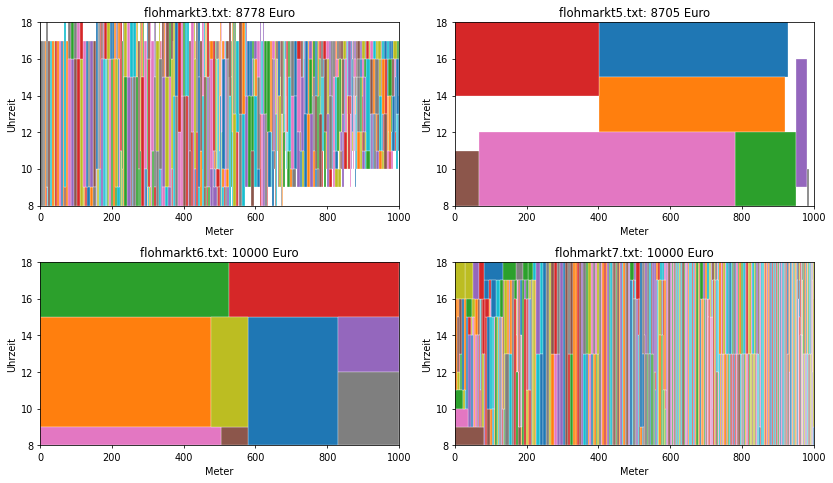

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle


def zeichne(nr, achse):
    anm = lies(nr)
    farben = plt.rcParams['axes.prop_cycle'].by_key()['color']
    for k, (i, x) in enumerate(sorted(beste_loesung[nr].items())):
        von, bis, laenge = anm[i]
        achse.add_patch(Rectangle((x, von), laenge, bis - von, facecolor=farben[k % len(farben)], edgecolor='white', linewidth=0.3))
    achse.set_xlim(0, 1000)
    achse.set_ylim(8, 18)
    achse.set_xlabel('Meter')
    achse.set_ylabel('Uhrzeit')
    achse.set_title('flohmarkt%d.txt: %d Euro' % (nr, einnahmen(anm, beste_loesung[nr])))


fig, achsen = plt.subplots(2, 2, figsize=(12, 7))
for achse, nr in zip(achsen.flatten(), [3, 5, 6, 7]):
    zeichne(nr, achse)
plt.tight_layout()
plt.show()

## Zum Schluss: Mit MiniZinc

Die Aufgabe lässt sich direkt als Modell aufschreiben, ganz wie in der Formalisierung der Lösungshinweise: Für jede Anmeldung `i` gibt es
eine Entscheidung `k[i]` (angenommen oder nicht) und den ersten Meter `x[i]`. Du kennst von den Arbeitsblättern zu MiniZinc `forall`,
`sum … where` und `.dzn`-Dateien. Neu sind hier die logischen Verknüpfungen: `/\` ist „und“, `\/` ist „oder“, `A -> B` heißt „wenn A,
dann B“. Ein `var bool` zählt in einer Summe als 0 oder 1.

```minizinc
int: n;                                    % Zahl der Anmeldungen
array[1..n] of int: von;
array[1..n] of int: bis;
array[1..n] of int: laenge;

array[1..n] of var bool: k;                % Anmeldung i angenommen?
array[1..n] of var 0..1000: x;             % erster Meter des Standes i
constraint forall(i in 1..n)(x[i] + laenge[i] <= 1000);

% zwei angenommene Stände, die sich zeitlich überschneiden, stehen nebeneinander
constraint forall(i, j in 1..n where i < j /\ von[i] < bis[j] /\ von[j] < bis[i])(
  (k[i] /\ k[j]) -> (x[i] + laenge[i] <= x[j] \/ x[j] + laenge[j] <= x[i]));

var int: einnahmen = sum(i in 1..n)(k[i] * (bis[i] - von[i]) * laenge[i]);
solve maximize einnahmen;
output ["einnahmen = \(einnahmen)\n", "angenommen: \([i | i in 1..n where fix(k[i])])\n"];
```

Die Bedingung schreiben wir nur für Paare auf, die sich zeitlich überschneiden (`where` mit festen Daten); für alle anderen Paare gibt es
nichts zu prüfen. `fix(k[i])` in der Ausgabe liest den Wert einer Variablen in der Lösung. Die Datendatei erzeugt Python:

In [ ]:
def als_dzn(anm):
    von = [a[0] for a in anm]
    bis = [a[1] for a in anm]
    laenge = [a[2] for a in anm]
    return 'n = %d;\nvon = %s;\nbis = %s;\nlaenge = %s;' % (len(anm), von, bis, laenge)


print(als_dzn(lies(4)))

n = 7;
von = [8, 15, 12, 8, 9, 8, 14];
bis = [15, 18, 15, 9, 15, 12, 18];
laenge = [249, 526, 520, 503, 477, 171, 401];


Für die kleinen Beispiele ist Chuffed sofort fertig. Die Ausgabe für `flohmarkt5.txt` (`==========` heißt: Optimum bewiesen):

**Ausgabe:**

```
einnahmen = 8705
angenommen: [2, 3, 6, 7, 9, 14, 19, 20]
----------
==========
```

Bei `flohmarkt4.txt` und `flohmarkt6.txt` beweist Chuffed ebenso schnell 7370 und 10 000. Bei den großen Beispielen sieht es ganz anders
aus. Beim Ausprobieren mit Zeitlimit 90 Sekunden fand Chuffed nur winzige Lösungen (Spalte „Chuffed“: beste Einnahmen bis zum Abbruch),
CP-SAT fand in derselben Zeit gar keine. „Paare“ ist die Zahl der Bedingungen, die das `forall` erzeugt.

| Beispiel | Anmeldungen | Paare | Chuffed | unser Ergebnis |
|----------|-------------|-------|---------|----------------|
| `flohmarkt1.txt` | 490 | 94601 | 51 | 8028 |
| `flohmarkt2.txt` | 603 | 144971 | 51 | 9077 |
| `flohmarkt3.txt` | 735 | 131745 | 63 | 8778 |
| `flohmarkt7.txt` | 566 | 123647 | 54 | 10000 |

(Beim Erzeugen dieses Notebooks mit Zeitlimit 60 Sekunden für `flohmarkt1.txt`: keine Antwort, Prozess nach 90 Sekunden beendet.) Schon das Übersetzen des Modells
dauert hier spürbar, und der Solver muss für Zehntausende von Paaren entscheiden, welcher Stand links steht. Die Beispiellösung der Hinweise
gibt ihrem Solver deshalb die Greedy-Lösung als Startpunkt mit (Warmstart), kommt damit aber bei den großen Beispielen auch nicht über
den Greedy hinaus. Für die großen Beispiele bleibt es also bei unseren Heuristiken.

### Eine obere Schranke

Was wir nicht schaffen, ist zu zeigen, dass 9077 und 8778 bei den Beispielen 2 und 3 optimal sind. Dafür lassen wir das Schwierige
weg: **wo** die Stände stehen. Übrig bleibt nur die Bedingung, dass zu jeder Stunde höchstens 1000 Meter vermietet sind. Jede echte
Belegung erfüllt diese Bedingung, also kann keine echte Belegung mehr einbringen als das Optimum dieses einfacheren Modells. Das ist eine
**obere Schranke**.

```minizinc
int: n;
array[1..n] of int: von;
array[1..n] of int: bis;
array[1..n] of int: laenge;

array[1..n] of var bool: k;                % Anmeldung i angenommen?
% zu jeder Stunde höchstens 1000 Meter (wo die Stände stehen, ist egal)
constraint forall(h in 8..17)(sum(i in 1..n where von[i] <= h /\ h < bis[i])(k[i] * laenge[i]) <= 1000);

var int: einnahmen = sum(i in 1..n)(k[i] * (bis[i] - von[i]) * laenge[i]);
solve maximize einnahmen;
output ["schranke = \(einnahmen)\n"];
```

Das Modell ist eine Art Rucksackproblem mit zehn Rucksäcken (Stunden). Wir lösen es mit HiGHS, einem Solver für **ganzzahlige lineare
Optimierung**, der bei MiniZinc dabei ist (Auswahl wie bei Chuffed über *Solver configuration*). Solche Solver sind für Summen mit
Ja/Nein-Variablen gemacht.

| Beispiel | Schranke (HiGHS) | unser Ergebnis |
|----------|------------------|----------------|
| `flohmarkt1.txt` | 8028 | 8028 |
| `flohmarkt2.txt` | 9077 | 9077 |
| `flohmarkt3.txt` | 8778 | 8778 |
| `flohmarkt4.txt` | 7370 | 7370 |
| `flohmarkt5.txt` | 8705 | 8705 |
| `flohmarkt6.txt` | 10000 | 10000 |
| `flohmarkt7.txt` | 10000 | 10000 |

Die Schranke ist in **allen** sieben Beispielen genau so groß wie unser Ergebnis. Damit ist bewiesen: Alle sieben Ergebnisse sind optimal,
auch 9077 bei `flohmarkt2.txt` und 8778 bei `flohmarkt3.txt`, die in den Lösungshinweisen als offen („?“) markiert sind. Dass diese Schranke
schon genügt, ist eine Eigenschaft der Beispiele und gilt nicht allgemein: Eine Auswahl, die zu jeder Stunde in 1000 Meter passt, lässt
sich nicht immer so anordnen, dass jeder Stand ein **zusammenhängendes** Stück bekommt. Hier haben wir aber zu jeder Schranke eine echte
Belegung gefunden, die sie erreicht, und mehr kann es nicht geben.

## Für Neugierige

- **Eine Schranke ganz ohne Solver** wäre: Zu jeder Stunde vermietet man höchstens 1000 Meter, aber auch höchstens so viele, wie gewünscht
  werden. Summiert über die zehn Stunden ergibt das eine Schranke, die man mit einer Zeile Python ausrechnet. Sie tut so, als könne man
  Stände stundenweise zerschneiden, und ist deshalb meist zu grob:

In [ ]:
for nr in (2, 3, 5):
    grob = sum(min(1000, meter) for meter in meter_je_stunde(lies(nr)))
    print('flohmarkt%d.txt: grobe Schranke %5d, unser Ergebnis %5d' % (nr, grob, ergebnis[nr]))

flohmarkt2.txt: grobe Schranke  9423, unser Ergebnis  9077
flohmarkt3.txt: grobe Schranke  8778, unser Ergebnis  8778
flohmarkt5.txt: grobe Schranke  9927, unser Ergebnis  8705


  Bei `flohmarkt2.txt` (9423) und `flohmarkt5.txt` (9927) liegt sie weit über dem Optimum. Bei `flohmarkt3.txt` ist sie aber schon genau
  8778: Hier beweist also bereits eine Zeile Python, dass unser Ergebnis optimal ist. (Unsere Belegung vermietet dort in jeder Stunde
  mit mehr als 1000 gewünschten Metern genau 1000 Meter und erfüllt in den Stunden mit weniger Wünschen, etwa von 17 bis 18 Uhr mit
  nur 363 Metern, alle Wünsche.)
- **Die Beispiellösung der Hinweise** formuliert die ganze Aufgabe als ganzzahliges lineares Programm (wie unser exaktes MiniZinc-Modell,
  die „oder“-Bedingung mit einer zusätzlichen Variablen und dem Faktor 1000 linearisiert) und startet den Solver mit der Greedy-Lösung
  nach Miete. Bei den großen Beispielen kommt der Solver damit nicht über den Greedy hinaus (8796, 8630, 9753).
- **Rechenaufwand:** Ein Greedy-Durchlauf prüft für jede Anmeldung höchstens 1000 Meter, also höchstens `1000 · n` Schritte. Eine Runde
  von „räumen und neu füllen“ prüft für jeden Kandidaten nur die Meter des Ausschnitts (höchstens 40). Darum schaffen wir 10 000 Runden.
- **Weitere Ideen** aus den Hinweisen: evolutionäre Algorithmen (viele Lösungen gleichzeitig, die man verändert und kreuzt) und Greedy-
  Verfahren, die nicht nach einer festen Reihenfolge gehen, sondern immer den Stand nehmen, der gerade am besten in eine Lücke passt.